Objective: Predict solar power output 15 minutes into the future using:
- 16 sky images covering the previous 15 minutes.
- Solar-power readings from the same period.
- Time information.

Compare a persistence baseline, traditional machine-learning models, and a convolutional neural network. 

In [1]:
%pip install -q pyarrow  #read the full dataset's Parquet files

Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path #import tool for working with file/folder locations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(1)

## Data Import

In [ ]:
import sys

project_folder = Path(
    "/Users/jackpaulson/Library/CloudStorage/"
    "OneDrive-UniversityofDenver 2/DU/" 
    "Fall 2026 Masters/Deep Learning/Project"
)

sys.path.insert(0, str(project_folder / "scripts"))  #add the scripts folder to Python's search locations. Used to find data_loader.py

from data_loader import SolarData  #bring in the class SolarData from the data_loader.py file in Scripts folder

data = SolarData(project_folder)  #load the full forecast records

image_indices = data.arrays["input_frame_ids"]  #get the 16 stored images belonging to each example

power_history = data.arrays["pv_history_kw"]  #get each example's 16 past power readings (kW)

time_features = data.calendar  #get four features representing time of day and time of year

targets = data.arrays["target_pv_kw"]  #get the power readings 15 minutes ahead (kW)

split = data.arrays["split"]  #get each example's training, validation, or test assignment

In [4]:
print("Unique images:", len(data.frames))  #count all original image-and-power records
print("Image sequences:", image_indices.shape)  #show the number of examples and images per example. 269,685 examples, each referring to 16 images
print("Power history:", power_history.shape)  #the 16 past power readings for each example
print("Time features:", time_features.shape)  #four time features for each example
print("Targets:", targets.shape)  #one future reading per example

print()
print("Training examples:", np.sum(split == "train"))  #examples available for model training
print("Validation examples:", np.sum(split == "validation"))  #count the examples used to compare and improve models
print("Test examples:", np.sum(split == "test"))  #count the examples reserved for final evaluation

Unique images: 363375
Image sequences: (269685, 16)
Power history: (269685, 16)
Time features: (269685, 4)
Targets: (269685,)

Training examples: 205735
Validation examples: 52910
Test examples: 11040


In [5]:
import pyarrow.parquet as pq

raw_folder = project_folder / "data" / "raw" / "solarbench" / "ground"   #find the source-data folder
raw_file = raw_folder / "train-00000-of-00005.parquet"  #select the first training-data file

parquet_file = pq.ParquetFile(raw_file)  #open the file
raw_data = parquet_file.read_row_group(0).to_pandas()  #read the first small group of records into a table

raw_data.head(10)

,image,time,pv
0,{'bytes': b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHD...,2017-03-09 06:47:00-08:00,0.055691
1,{'bytes': b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHD...,2017-03-09 06:48:00-08:00,0.088763
2,{'bytes': b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHD...,2017-03-09 06:49:00-08:00,0.109171
3,{'bytes': b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHD...,2017-03-09 06:50:00-08:00,0.123206
4,{'bytes': b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHD...,2017-03-09 06:51:00-08:00,0.159748
5,{'bytes': b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHD...,2017-03-09 06:52:00-08:00,0.187554
6,{'bytes': b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHD...,2017-03-09 06:53:00-08:00,0.246712
7,{'bytes': b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHD...,2017-03-09 06:54:00-08:00,0.305602
8,{'bytes': b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHD...,2017-03-09 06:55:00-08:00,0.377306
9,{'bytes': b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHD...,2017-03-09 06:56:00-08:00,0.359507


In [6]:
data.frames.head(10)  #show observation details

,frame_id,source_split,source_file,row_group,row_in_group,time_utc,time_local,local_date,pv_kw,image_pixel_sha256,image_std_0_255,split,usable
0,0,train,data/raw/solarbench/ground/train-00000-of-0000...,0,0,2017-03-09 14:47:00+00:00,2017-03-09 06:47:00-08:00,2017-03-09,0.055691,f4030c75fd11dff2bbd4481a0fda206b3b8b70fc4c6642...,61.218101,train,True
1,1,train,data/raw/solarbench/ground/train-00000-of-0000...,0,1,2017-03-09 14:48:00+00:00,2017-03-09 06:48:00-08:00,2017-03-09,0.088763,958ca3070bd16dbd5739e89ae897a3b93135608a8cf3c7...,61.449822,train,True
2,2,train,data/raw/solarbench/ground/train-00000-of-0000...,0,2,2017-03-09 14:49:00+00:00,2017-03-09 06:49:00-08:00,2017-03-09,0.109171,0e528f299199f5a41798e7dcc6267bc79740ccad411c52...,61.093403,train,True
3,3,train,data/raw/solarbench/ground/train-00000-of-0000...,0,3,2017-03-09 14:50:00+00:00,2017-03-09 06:50:00-08:00,2017-03-09,0.123206,4fd761a938993191889909f72cb16ab0d1be30a53d50db...,60.554987,train,True
4,4,train,data/raw/solarbench/ground/train-00000-of-0000...,0,4,2017-03-09 14:51:00+00:00,2017-03-09 06:51:00-08:00,2017-03-09,0.159748,8e446e4476a189ba617dd1203c63152d7bf06653ed0ef0...,60.407018,train,True
5,5,train,data/raw/solarbench/ground/train-00000-of-0000...,0,5,2017-03-09 14:52:00+00:00,2017-03-09 06:52:00-08:00,2017-03-09,0.187554,47ac671fc2986e16017ab7aa42489de7c6b9e3da3513d4...,60.277072,train,True
6,6,train,data/raw/solarbench/ground/train-00000-of-0000...,0,6,2017-03-09 14:53:00+00:00,2017-03-09 06:53:00-08:00,2017-03-09,0.246712,0ce8f9ca49ef1275d513d8d8a0c785d0716cc95254b05b...,59.886861,train,True
7,7,train,data/raw/solarbench/ground/train-00000-of-0000...,0,7,2017-03-09 14:54:00+00:00,2017-03-09 06:54:00-08:00,2017-03-09,0.305602,63a2011d2df84723e246b2285d29eeaea8ea2c698c36b2...,60.159187,train,True
8,8,train,data/raw/solarbench/ground/train-00000-of-0000...,0,8,2017-03-09 14:55:00+00:00,2017-03-09 06:55:00-08:00,2017-03-09,0.377306,0c7d9a1f53e836e1b8d08f8445367cd82da4f1d09c7887...,59.680051,train,True
9,9,train,data/raw/solarbench/ground/train-00000-of-0000...,0,9,2017-03-09 14:56:00+00:00,2017-03-09 06:56:00-08:00,2017-03-09,0.359507,74020474ae24a74694973244a6cb66e26a2cbd2a06f24c...,59.806337,train,True


In [7]:
data.samples.loc[data.samples["split"] == "train"].head(10)  #each row represents one prediction the model makes

,sample_id,split,issue_frame_id,target_frame_id,issue_time_utc,target_time_utc,local_date,target_pv_kw,persistence_kw,pilot
11040,11040,train,15,30,2017-03-09 15:02:00+00:00,2017-03-09 15:17:00+00:00,2017-03-09,1.493554,0.546516,True
11041,11041,train,16,31,2017-03-09 15:03:00+00:00,2017-03-09 15:18:00+00:00,2017-03-09,1.569899,0.601256,True
11042,11042,train,17,32,2017-03-09 15:04:00+00:00,2017-03-09 15:19:00+00:00,2017-03-09,1.682637,0.656523,True
11043,11043,train,18,33,2017-03-09 15:05:00+00:00,2017-03-09 15:20:00+00:00,2017-03-09,1.777972,0.700257,True
11044,11044,train,19,34,2017-03-09 15:06:00+00:00,2017-03-09 15:21:00+00:00,2017-03-09,1.859009,0.761019,True
11045,11045,train,20,35,2017-03-09 15:07:00+00:00,2017-03-09 15:22:00+00:00,2017-03-09,1.946541,0.813864,True
11046,11046,train,21,36,2017-03-09 15:08:00+00:00,2017-03-09 15:23:00+00:00,2017-03-09,2.004047,0.862825,True
11047,11047,train,22,37,2017-03-09 15:09:00+00:00,2017-03-09 15:24:00+00:00,2017-03-09,2.090795,0.917141,True
11048,11048,train,23,38,2017-03-09 15:10:00+00:00,2017-03-09 15:25:00+00:00,2017-03-09,2.213165,0.989677,True
11049,11049,train,24,39,2017-03-09 15:11:00+00:00,2017-03-09 15:26:00+00:00,2017-03-09,2.343655,1.055411,True


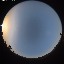

In [8]:
import io
from PIL import Image 
from IPython.display import display  #display the image inside the notebook

image_bytes = raw_data.iloc[0]["image"]["bytes"]  # Get the image bytes from the first record.
image = Image.open(io.BytesIO(image_bytes))  # Turn those bytes into an image.
display(image)  # Show the image.

## Inspect One Training Example

In [ ]:
training_example = np.flatnonzero(split == "train")[0]  #get the first training example

training_example_indices = image_indices[training_example]  #get the references to this example's 16 images

training_example_power = power_history[training_example]  #get the 16 past power readings (kW)

training_example_target = targets[training_example]  #get the actual power reading 15 minutes ahead (kW)

print("Example index:", training_example)  #show the forecasting example selected
print("Number of input images:", len(training_example_indices)) 
print("Latest power reading:", round(float(training_example_power[-1]), 3), "kW")
print("Power 15 minutes later:", round(float(training_example_target), 3), "kW")


Example index: 11040
Number of input images: 16
Latest power reading: 0.547 kW
Power 15 minutes later: 1.494 kW


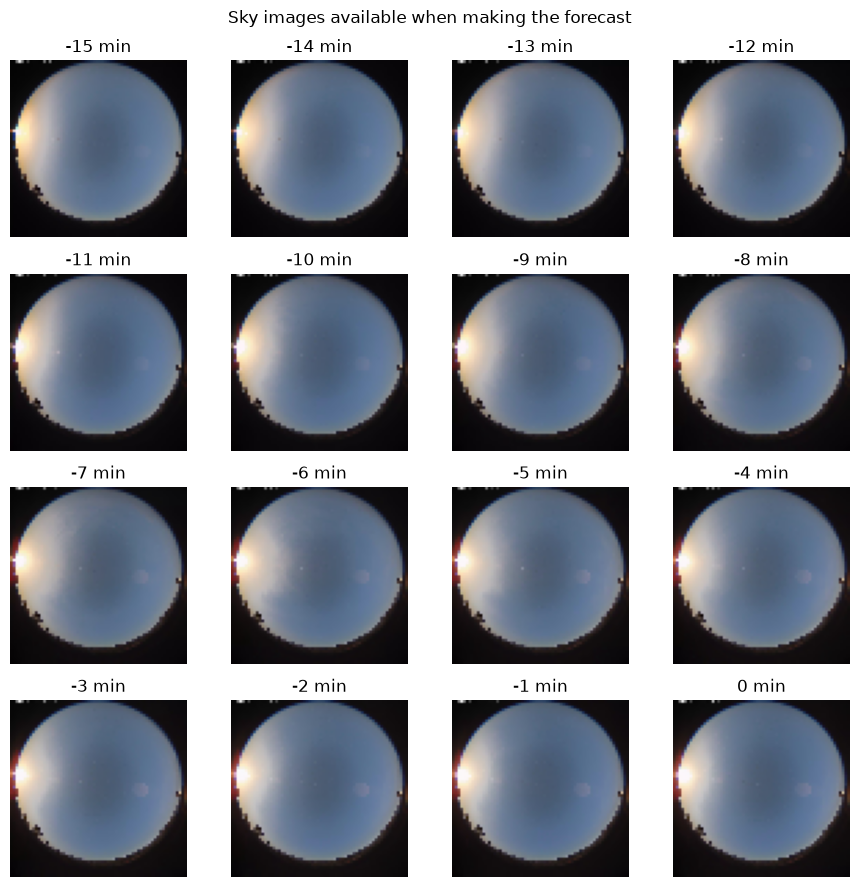

In [18]:
figure, axes = plt.subplots(4, 4, figsize=(9, 9))

for position, axis in enumerate(axes.flat):
    frame_id = int(training_example_indices[position])  #find the image reference for this position
    sky_image = data.image(frame_id)  #read that image from the full dataset
    axis.imshow(sky_image)
    axis.set_title(f"{position - 15} min")
    axis.axis("off")

figure.suptitle("Sky images available when making the forecast")
plt.tight_layout()
plt.show()

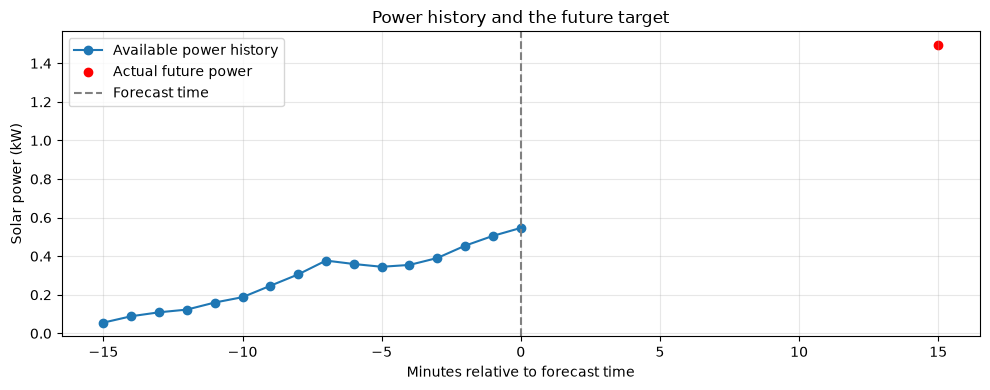

In [19]:
history_minutes = np.arange(-15, 1)  #create the 16 time positions from 15 minutes before the forecast through the forecast time

plt.figure(figsize=(10, 4)) 
plt.plot(history_minutes, training_example_power, "o-", label="Available power history")
plt.scatter(15, training_example_target, color="red", label="Actual future power")  #show the actual power 15 minutes after the forecast time
plt.axvline(0, color="gray", linestyle="--", label="Forecast time")
plt.xticks(np.arange(-15, 16, 5))
plt.xlabel("Minutes relative to forecast time")
plt.ylabel("Solar power (kW)")
plt.title("Power history and the future target")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Explore Training Data

In [ ]:
#Select the training observations and summarize them

training_frames = data.frames.loc[data.frames["split"] == "train"].copy()  #creates a separate table containing the training observations

print("Training observations: ", len(training_frames))  #counts the individual image and power records
#len(training_frames) counts the table’s rows. Each row represents one image, its timestamp, and its matching power reading

print()
print("Training days:", training_frames["local_date"].nunique())  #counts the unique calendar days training data was recorded

print()
training_frames["pv_kw"].describe()  #data on the power readings


Training observations:  279072

Training days: 396



count    279072.000000
mean         13.279804
std           7.926389
min           0.000020
25%           5.753787
50%          14.572582
75%          20.588566
max          29.585369
Name: pv_kw, dtype: float64

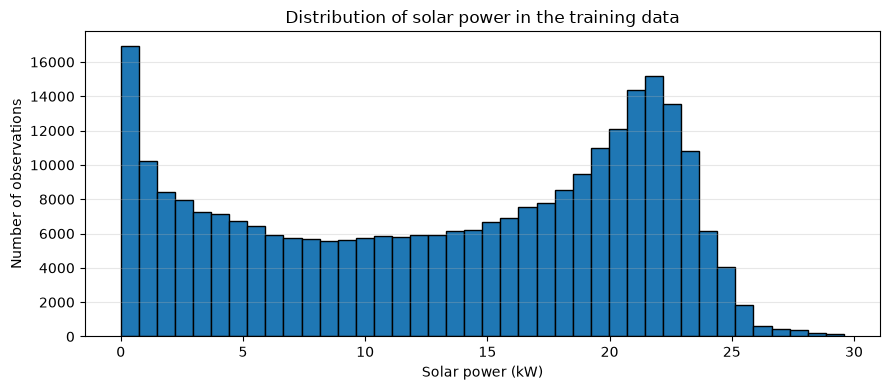

In [ ]:
#Plot the distribution of power readings

plt.figure(figsize=(9, 4))
plt.hist(training_frames["pv_kw"], bins=40, edgecolor="black")
plt.xlabel("Solar power (kW)")
plt.ylabel("Number of observations")
plt.title("Distribution of solar power in the training data")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
#Select the first three training days

training_dates = np.sort(training_frames["local_date"].unique())  #gets the training dates in chronological order

selected_dates = training_dates[:3] #first 3 training dates

print("Selected training dates: ", selected_dates)

Selected training dates:  ['2017-03-09' '2017-05-12' '2017-05-15']


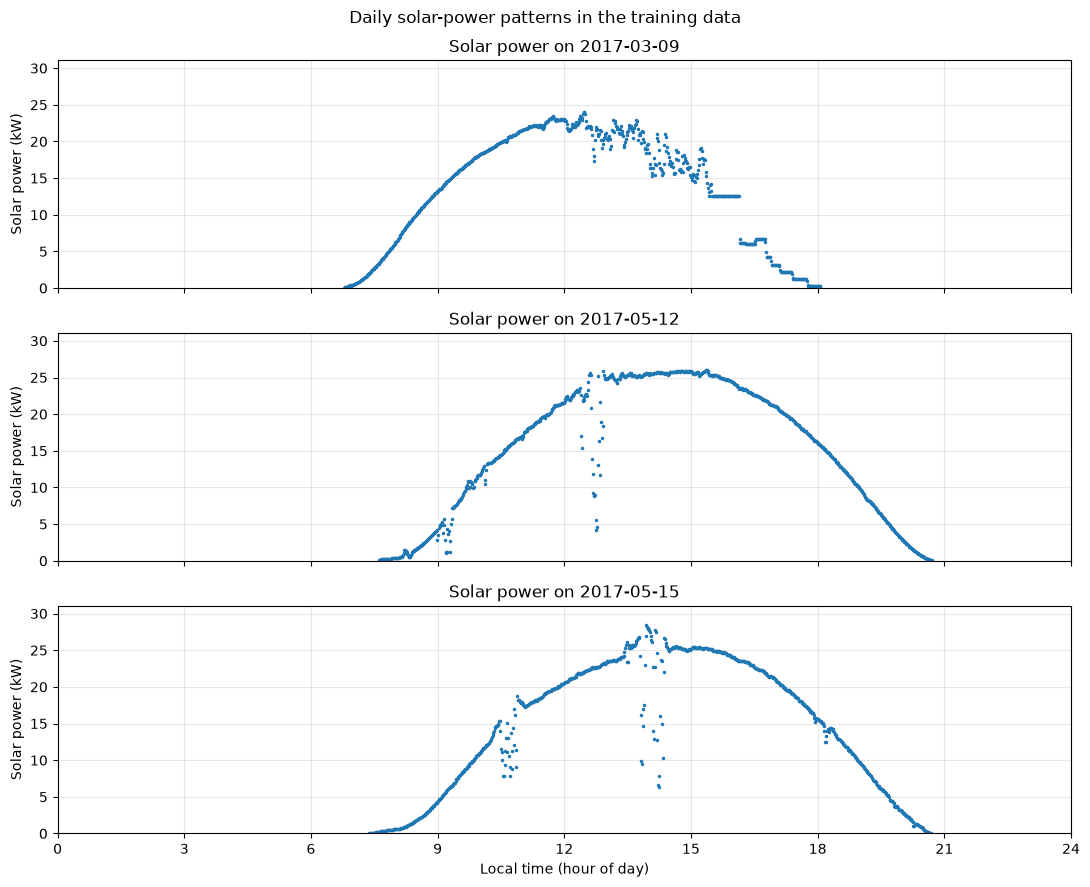

In [38]:
#Plot the first three training days power readings

figure, axes = plt.subplots(3, 1, figsize=(11, 9), sharex=True, sharey=True)

for axis, selected_date in zip(axes, selected_dates):
    day_data = training_frames.loc[training_frames["local_date"] == selected_date].copy()
    day_data = day_data.sort_values("time_local")  #put the observations in time order.
    local_time = day_data["time_local"]  #get the observation timestamps in local time.
    local_hours = local_time.dt.hour + local_time.dt.minute / 60 + local_time.dt.second / 3600  #convert each timestamp into an hour value (Ex. such as 6.5 for 6:30 AM)

    axis.plot(local_hours, day_data["pv_kw"], ".", markersize=3)
    axis.set_title(f"Solar power on {selected_date}")
    axis.set_ylabel("Solar power (kW)")
    axis.set_xlim(0, 24)
    axis.set_ylim(bottom=0)
    axis.set_xticks(np.arange(0, 25, 3))
    axis.grid(alpha=0.3)

axes[0].set_ylim(0, training_frames["pv_kw"].max() * 1.05)
axes[-1].set_xlabel("Local time (hour of day)")
figure.suptitle("Daily solar-power patterns in the training data")
plt.tight_layout()
plt.show()

## Analyze Data Quality

In [ ]:
#Check for missing / invalid data

quality_checks = {
    "Missing timestamps": training_frames["time_local"].isna().sum(), #counts the observations without a timestamp
    
    "Missing power readings": training_frames["pv_kw"].isna().sum(), #counts the observations without a power reading
    
    "Negative power readings": (training_frames["pv_kw"] < 0).sum(), #counts negative power readings
    
    "Duplicate timestamps": training_frames["time_local"].duplicated().sum(), #counts repeated observation timesteamps
}

pd.Series(quality_checks)

Missing timestamps         0
Missing power readings     0
Negative power readings    0
Duplicate timestamps       0
dtype: int64

In [52]:
#Check the time between observations

ordered_training_frames = training_frames.sort_values(["local_date", "time_local"])

daily_training_groups = ordered_training_frames.groupby("local_date") #group training observations belonging to the same day

daily_training_times = daily_training_groups["time_local"] #select the timestamp within each days group

time_differences = daily_training_times.diff() #subtracts the pervious timestamp from the current timestamp within each day

time_intervals = time_differences.dt.total_seconds() #convert the time differences into number of seconds

time_intervals = time_intervals.dropna() #exclude each days first observation because it has no previous reading that day

print("Intervals exactly 60 seconds: ", (time_intervals == 60).sum())  #count observations spaced exactly 60 seconds apart
print("Intervals longer than 60 seconds ", (time_intervals > 60).sum()) #count observations spaced more than 60 seconds apart
print("Intervals shorter than 60 seconds ", (time_intervals < 60).sum()) #count observations spaced less than 60 seconds apart


Intervals exactly 60 seconds:  276508
Intervals longer than 60 seconds  174
Intervals shorter than 60 seconds  1994


In [56]:
#Get the timestamps for each training example

training_example_ids = np.flatnonzero(split == "train") #get the positions of all the training examples

training_frame_ids = image_indices[training_example_ids] #get the 16 image references for each training example

training_target_ids = data.arrays["target_frame_ids"][training_example_ids] #get the reference to each example's future target observation

frame_times = data.frames["time_utc"].to_numpy(dtype="datetime64[ns]")  #convert the UTC timestamps into NumPy date-and-time values

training_input_times = frame_times[training_frame_ids]  #get the timestamps of all training input images

training_target_times = frame_times[training_target_ids]  #get the timestamp of each training target

In [ ]:
#Check the input spacing and forecast horizon

input_spacing_seconds = np.diff(training_input_times, axis = 1) / np.timedelta64(1, "s")  #calculate the seconds between neighboring input images for each example

target_delay_minutes = (training_target_times - training_input_times[:, -1]) / np.timedelta64(1, "m")  # Calculate the minutes between the final input and its future target

print("Training examples checked:", len(training_example_ids))  #how many training examples were checked
print("Examples with incorrect input spacing:", np.any(input_spacing_seconds != 60, axis = 1).sum())  #count examples with any input interval other than 60 seconds
print("Examples with incorrect forecast horizon:", (target_delay_minutes != 15).sum())  #count examples whose target is not exactly 15 minutes ahead

Training examples checked: 205735
Examples with incorrect input spacing: 0
Examples with incorrect forecast horizon: 0


## Data Splits

In [59]:
#Get the dates for the training, validation, and test set

training_days = set(data.samples.loc[data.samples["split"] == "train", "local_date"])  #unique dates for training examples
validation_days = set(data.samples.loc[data.samples["split"] == "validation", "local_date"])  #unique dates for validation examples
test_days = set(data.samples.loc[data.samples["split"] == "test", "local_date"])  #unique dates for test examples

print("Training days:", len(training_days))
print("Validation days:", len(validation_days))
print("Test days:", len(test_days))

Training days: 396
Validation days: 101
Test days: 20


In [ ]:
#Check for overlapping dates in the training, validation, and test sets

training_validation_overlap = training_days.intersection(validation_days) #find any dates shared by training and validation
training_test_overlap = training_days.intersection(test_days) #find any dates shared by training and testing
validation_test_overlap = validation_days.intersection(test_days) #find any dates shared by validation and testing

print("Days shared by training and validation:", len(training_validation_overlap))
print("Days shared by training and testing:", len(training_test_overlap))
print("Days shared by validation and testing:", len(validation_test_overlap))

Days shared by training and validation: 0
Days shared by training and testing: 0
Days shared by validation and testing: 0
